# 02 — Audit Pengelompokan Nama File dan Frozen Split

## Tujuan dan batas analisis

**Pertanyaan:** bagaimana prefix nama file dikelompokkan untuk mengurangi kebocoran antar subset, dan apakah `split_manifest.csv` yang dibekukan memenuhi syarat pemisahan grup, sidik jari piksel, serta representasi enam kategori?

**Artefak input:**
- `data/metadata/split_manifest.csv` dan `data/metadata/split_manifest.sha256`
- `data/metadata/filename_groups.csv`
- `data/metadata/manifest.csv`

**Batas eksekusi:** notebook ini hanya memverifikasi *frozen split* yang sudah ada secara *read-only* tanpa mengeksekusi ulang pembuatan *split* atau menyentuh citra `test`.

In [1]:
%matplotlib inline

from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ebhi_dip import (
    ALLOWED_SPLITS,
    EXPECTED_CATEGORIES,
    canonical_group_id,
    configure_notebook_style,
    find_project_root,
    finish_figure,
    load_split_manifest,
    sha256_bytes,
    verify_frozen_split,
)

PROJECT_ROOT_OVERRIDE = None
EXPORT_FIGURES = False

ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
SPLIT_SHA = verify_frozen_split(ROOT)
configure_notebook_style()

source_files = {
    "split_manifest": ROOT / "data/metadata/split_manifest.csv",
    "split_sha": ROOT / "data/metadata/split_manifest.sha256",
    "filename_groups": ROOT / "data/metadata/filename_groups.csv",
    "manifest": ROOT / "data/metadata/manifest.csv",
}
input_hashes_before = {name: sha256_bytes(path) for name, path in source_files.items()}

print("Verified frozen split SHA-256:", SPLIT_SHA)
display(
    pd.DataFrame(
        {
            "komponen": ["Python", "NumPy", "pandas", "Matplotlib"],
            "versi": [platform.python_version(), np.__version__, pd.__version__, matplotlib.__version__],
        }
    )
)

Verified frozen split SHA-256: ceeba8e282f77cdb78a9675618b3dcb6729fbc2339e2d112085a11720fc9108d


,komponen,versi
0,Python,3.14.0
1,NumPy,2.5.4
2,pandas,3.1.1
3,Matplotlib,3.11.2


## 1. Rasional pengelompokan prefix nama file dan kapitalisasi

Token pertama nama file sebelum tanda `-` sering berulang pada beberapa potongan citra. Karena terdapat variasi penulisan huruf besar/kecil (misalnya `GTxc...` dan `GTXC...`), `group_id` dinormalisasi menjadi *uppercase* lintas seluruh kategori.

In [2]:
split_df = load_split_manifest(ROOT, verify=False)
raw_groups_df = pd.read_csv(source_files["filename_groups"], encoding="utf-8-sig")

split_df["raw_prefix"] = split_df["image_path"].map(lambda p: Path(p).stem.split("-")[0])
assert (split_df["raw_prefix"].str.upper() == split_df["group_id"]).all()
assert (split_df["image_path"].map(canonical_group_id) == split_df["group_id"]).all()

case_variants = (
    split_df.groupby("group_id", observed=True)
    .agg(
        raw_variants=("raw_prefix", lambda s: " | ".join(sorted(set(s)))),
        variant_count=("raw_prefix", "nunique"),
        image_count=("sample_id", "size"),
        categories=("category", lambda s: " | ".join(sorted(set(s)))),
    )
)
collisions = case_variants.loc[case_variants["variant_count"] > 1].copy()

grouping_overview = pd.DataFrame(
    [
        {"metrik": "Citra berpasangan dalam frozen split", "nilai": len(split_df)},
        {"metrik": "Prefix mentah peka kapitalisasi (filename_groups.csv)", "nilai": len(raw_groups_df)},
        {"metrik": "Canonical group_id (uppercase)", "nilai": split_df["group_id"].nunique()},
        {"metrik": "Grup dengan kolisi kapitalisasi", "nilai": len(collisions)},
        {"metrik": "Canonical group dengan >1 citra", "nilai": int((case_variants["image_count"] > 1).sum())},
        {"metrik": "Canonical group muncul lintas >1 kategori", "nilai": int(split_df.groupby("group_id")["category"].nunique().gt(1).sum())},
    ]
)
display(grouping_overview)
display(collisions.head(10))

,metrik,nilai
0,Citra berpasangan dalam frozen split,2226
1,Prefix mentah peka kapitalisasi (filename_grou...,365
2,Canonical group_id (uppercase),353
3,Grup dengan kolisi kapitalisasi,12
4,Canonical group dengan >1 citra,299
5,Canonical group muncul lintas >1 kategori,74


,raw_variants,variant_count,image_count,categories
group_id,,,,
GTXC2012436,GTXC2012436 | GTxc2012436,2,7,Adenocarcinoma | High-grade IN
GTXC2013066,GTXC2013066 | GTxc2013066,2,9,Low-grade IN | Polyp
GTXC2013391,GTXC2013391 | GTxc2013391,2,14,Adenocarcinoma | Polyp
GTXC2014065,GTXC2014065 | GTxc2014065,2,14,Adenocarcinoma
GTXC2014129,GTXC2014129 | GTxc2014129,2,19,Low-grade IN | Serrated adenoma
GTXC2014131,GTXC2014131 | GTxc2014131,2,20,Adenocarcinoma | High-grade IN
GTXC2014134,GTXC2014134 | GTxc2014134,2,2,Polyp
GTXC2014136,GTXC2014136 | GTxc2014136,2,4,Low-grade IN
GTXC2014144,GTXC2014144 | GTxc2014144,2,35,Adenocarcinoma | High-grade IN | Low-grade IN


**Keterbatasan penting pengelompokan.** `group_id` berbasis token nama file adalah **kunci pengelompokan sementara (*provisional grouping keys*), belum terverifikasi sebagai ID pasien klinis**. Normalisasi *uppercase* menyatukan varian penulisan prefix yang sama ke dalam **353 grup kanonik** agar tidak tersebar antar `train`, `val`, dan `test`.

## 2. Verifikasi ketiadaan tumpang tindih (*zero overlap*) antar subset

In [3]:
overlap_rows = []
for col in ("sample_id", "group_id", "pixel_sha256"):
    sets = {sp: set(split_df.loc[split_df["split"].eq(sp), col]) for sp in ALLOWED_SPLITS}
    overlap_rows.append(
        {
            "kunci_integritas": col,
            "train_unik": len(sets["train"]),
            "val_unik": len(sets["val"]),
            "test_unik": len(sets["test"]),
            "overlap_train_val": len(sets["train"] & sets["val"]),
            "overlap_train_test": len(sets["train"] & sets["test"]),
            "overlap_val_test": len(sets["val"] & sets["test"]),
        }
    )
overlap_table = pd.DataFrame(overlap_rows).set_index("kunci_integritas")
display(overlap_table)

assert (overlap_table[["overlap_train_val", "overlap_train_test", "overlap_val_test"]].to_numpy() == 0).all()
assert len(split_df) == 2226
assert split_df["split"].value_counts().to_dict() == {"train": 1535, "val": 372, "test": 319}

,train_unik,val_unik,test_unik,overlap_train_val,overlap_train_test,overlap_val_test
kunci_integritas,,,,,,
sample_id,1535,372,319,0,0,0
group_id,247,53,53,0,0,0
pixel_sha256,1535,372,319,0,0,0


## 3. Distribusi citra dan grup per kategori terhadap target 70 / 15 / 15

split,train,val,test,total_images,train_pct,val_pct,test_pct,train_groups,val_groups,test_groups
category,,,,,,,,,,
Adenocarcinoma,540,131,124,795,67.92,16.48,15.60,75,15,17
High-grade IN,131,20,35,186,70.43,10.75,18.82,28,5,10
Low-grade IN,444,107,86,637,69.70,16.80,13.50,101,21,22
Normal,54,10,12,76,71.05,13.16,15.79,11,3,2
Polyp,324,96,54,474,68.35,20.25,11.39,81,21,14
Serrated adenoma,42,8,8,58,72.41,13.79,13.79,10,2,1


,images,image_share_pct,canonical_groups
split,,,
train,1535,68.96,247
val,372,16.71,53
test,319,14.33,53


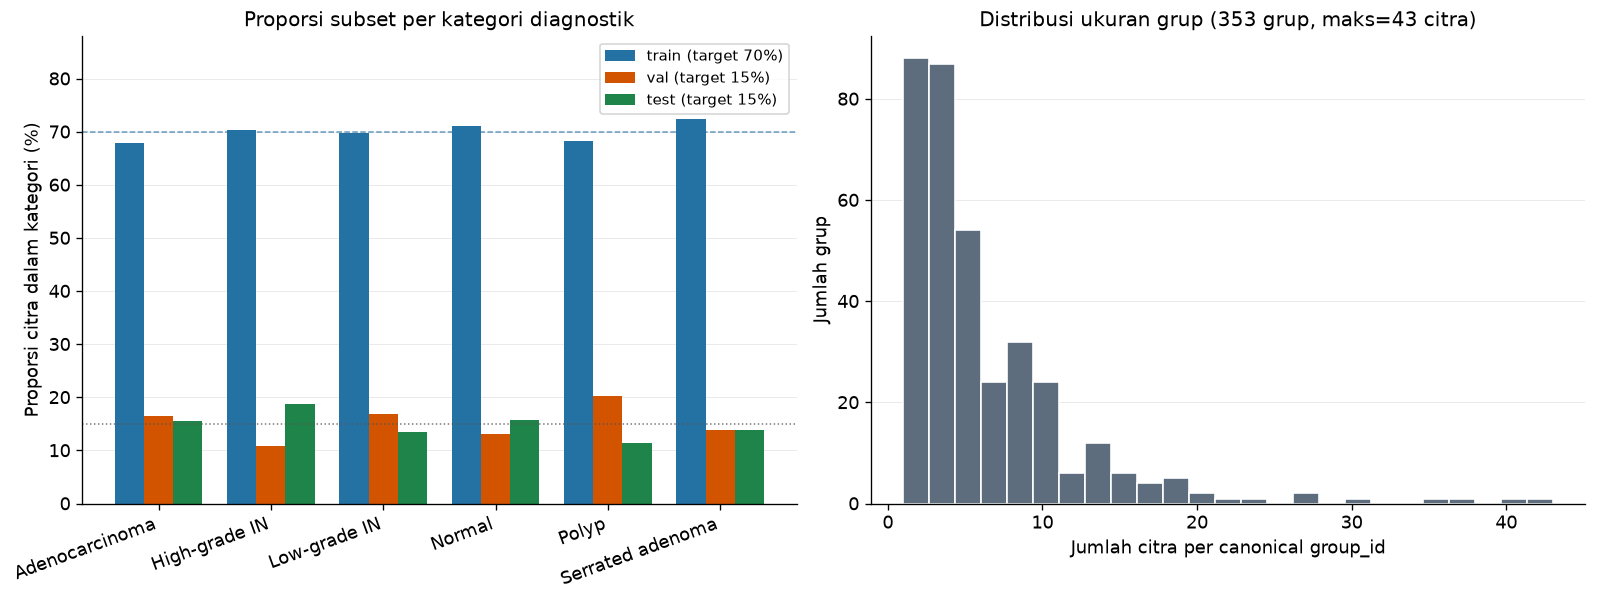

In [4]:
img_counts = (
    split_df.pivot_table(index="category", columns="split", values="sample_id", aggfunc="count", fill_value=0)
    .reindex(index=list(EXPECTED_CATEGORIES), columns=list(ALLOWED_SPLITS))
)
img_counts["total_images"] = img_counts.sum(axis=1)
for sp in ALLOWED_SPLITS:
    img_counts[f"{sp}_pct"] = (100.0 * img_counts[sp] / img_counts["total_images"]).round(2)

grp_counts = (
    split_df.pivot_table(index="category", columns="split", values="group_id", aggfunc="nunique", fill_value=0)
    .reindex(index=list(EXPECTED_CATEGORIES), columns=list(ALLOWED_SPLITS))
    .rename(columns={sp: f"{sp}_groups" for sp in ALLOWED_SPLITS})
)

dist_table = pd.concat([img_counts, grp_counts], axis=1)
display(dist_table)

subset_totals = pd.DataFrame(
    [
        {
            "split": sp,
            "images": int((split_df["split"] == sp).sum()),
            "image_share_pct": round(100.0 * float((split_df["split"] == sp).mean()), 2),
            "canonical_groups": int(split_df.loc[split_df["split"] == sp, "group_id"].nunique()),
        }
        for sp in ALLOWED_SPLITS
    ]
).set_index("split")
display(subset_totals)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.9), layout="constrained")
x = np.arange(len(EXPECTED_CATEGORIES))
width = 0.26
colors = {"train": "#2471A3", "val": "#D35400", "test": "#1E8449"}
for idx, sp in enumerate(ALLOWED_SPLITS):
    axes[0].bar(
        x + (idx - 1) * width,
        img_counts[f"{sp}_pct"],
        width=width,
        color=colors[sp],
        label=f"{sp} (target {'70%' if sp == 'train' else '15%'})",
    )
axes[0].axhline(70.0, color="#2471A3", linestyle="--", linewidth=0.9, alpha=0.7)
axes[0].axhline(15.0, color="#555555", linestyle=":", linewidth=0.9, alpha=0.8)
axes[0].set_xticks(x, list(EXPECTED_CATEGORIES))
plt.setp(axes[0].get_xticklabels(), rotation=20, ha="right")
axes[0].set_ylabel("Proporsi citra dalam kategori (%)")
axes[0].set_ylim(0, 88)
axes[0].set_title("Proporsi subset per kategori diagnostik")
axes[0].legend(frameon=True, fontsize=8.8)
axes[0].grid(axis="y", color="#EAEAEA", linewidth=0.6)

group_sizes = split_df.groupby("group_id", observed=True).size()
axes[1].hist(group_sizes, bins=25, color="#5D6D7E", edgecolor="white")
axes[1].set_xlabel("Jumlah citra per canonical group_id")
axes[1].set_ylabel("Jumlah grup")
axes[1].set_title(f"Distribusi ukuran grup (353 grup, maks={int(group_sizes.max())} citra)")
axes[1].grid(axis="y", color="#EAEAEA", linewidth=0.6)

export_target = (ROOT / "reports/figures/02_split_distribution.png") if EXPORT_FIGURES else None
finish_figure(fig, export_path=export_target)

## Ringkasan dan batas metodologis

- **Observasi:** `split_manifest.csv` cocok secara *raw-byte* dengan `split_manifest.sha256` (`ceeba8e2...`), membagi 2.226 citra menjadi `1.535 train` (`247` grup), `372 val` (`53` grup), dan `319 test` (`53` grup) tanpa kebocoran `group_id` maupun `pixel_sha256`.
- **Implikasi metrik:** ukuran kategori tidak sama (misalnya pada `val`: `Adenocarcinoma` memiliki 131 citra sedangkan `Serrated adenoma` 8 citra), sehingga metrik utama menggunakan **rerata skor per kategori terlebih dahulu, lalu rerata bobot sama lintas enam kategori**.

In [5]:
input_hashes_after = {name: sha256_bytes(path) for name, path in source_files.items()}
assert input_hashes_after == input_hashes_before, "Artefak split berubah saat audit dijalankan."
print("Selesai: frozen split utuh (train=1535, val=372, test=319; overlap=0).")

Selesai: frozen split utuh (train=1535, val=372, test=319; overlap=0).
